# Data preprocessing

## Import required libraries

In [24]:
import os
import json
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

## Mount Google Drive

In [25]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Organize paths

In [ ]:
DATA_PATH = "/content/drive/MyDrive/Applied AI VQA Project/VQA Dataset/"
questions_file = DATA_PATH + "questions/v2_OpenEnded_mscoco_val2014_questions.json"
annotations_file = DATA_PATH + "annotations/v2_mscoco_val2014_annotations.json"
images_path = DATA_PATH + "images/val2014/"

# Check if the directory exists before trying to list its contents
if os.path.isdir(images_path):
    image_files = os.listdir(images_path)
    print(f"Found {len(image_files)} image files in {images_path}")
else:
    print(f"Error: Image directory not found at {images_path}. Please verify the path.")
    image_files = [] # Initialize as empty list to prevent further errors

df = pd.read_csv(DATA_PATH + "VQA_Dataset.csv")

Found 40504 image files in ../../VQA Dataset/images/val2014/


## Pytorch Environment


In [27]:
import torch
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("Device name:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

PyTorch version: 2.10.0+cu128
CUDA available: True
Device name: Tesla T4


## Image Preprocessing

### Image Resolution inspectation

In [28]:
from PIL import Image
for img_name in image_files[:5]:
    img = Image.open(os.path.join(images_path, img_name))
    print(img_name, img.size)

COCO_val2014_000000125371.jpg (500, 400)
COCO_val2014_000000513280.jpg (426, 640)
COCO_val2014_000000421979.jpg (480, 640)
COCO_val2014_000000547601.jpg (426, 640)
COCO_val2014_000000022563.jpg (426, 640)


We definitly need an image resolution transformation

### Image Transformation

In [29]:
from torchvision import transforms

image_transform = transforms.Compose([
    transforms.Resize((224, 224)),          # resize images
    transforms.ToTensor(),                  # convert to tensor [0,1]
    transforms.Normalize(                   # ImageNet normalization
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

### Image Dataset Class

In [30]:
import os
from PIL import Image
import matplotlib.pyplot as plt
from torch.utils.data import Dataset


class ImageDataset(Dataset):
    def __init__(self, images_path, image_ids, transform=None):
        """
        PyTorch Dataset for loading images from COCO VQA dataset.

        Parameters
        ----------
        images_path : str
            Path to the directory containing images.
        image_ids : list
            List of image IDs (integers).
        transform : callable, optional
            Transformations to apply to each image (e.g., resize, normalization).
        """
        self.images_path = images_path
        self.image_ids = image_ids
        self.transform = transform

    def __len__(self):
        """
        Return the total number of images.
        """
        return len(self.image_ids)

    def __getitem__(self, index):
        """
        Load a single image and return it with its image_id.

        Parameters
        ----------
        index : int
            Index of the sample.

        Returns
        -------
        img : Tensor or PIL Image
            Transformed image.
        image_id : int
            Corresponding image ID.
        """
        image_id = self.image_ids[index]
        image_name = f"COCO_val2014_{image_id:012d}.jpg"
        image_path = os.path.join(self.images_path, image_name)

        try:
            img = Image.open(image_path).convert("RGB")
        except FileNotFoundError:
            # Handle missing image gracefully
            raise FileNotFoundError(f"Image not found: {image_path}")

        if self.transform:
            img = self.transform(img)

        return img, image_id

### Create dataset

In [31]:
image_ids = df["image_id"].values
dataset = ImageDataset(images_path, image_ids, transform=image_transform)

### Sanity check to see the image, question and answer representation

In [32]:
import numpy as np
import matplotlib.pyplot as plt

def sanity_check_vqa_df(dataset, df, index=None):
    """
    Sanity check function to visualize an image with all its Q&A pairs using a DataFrame.

    Parameters
    ----------
    dataset : PyTorch Dataset
        Dataset returning (image_tensor, image_id)
    df : pandas.DataFrame
        Must contain columns ['image_id', 'question', 'answer']
    index : int, optional
        Index to visualize. If None, a random sample is selected.
    """

    # 1. Select random index if not provided
    if index is None:
        index = np.random.randint(0, len(dataset))

    img_tensor, image_id = dataset[index]

    # 2. Convert tensor -> numpy for display
    img_np = img_tensor.clone()

    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])

    img_np = img_np.permute(1, 2, 0).numpy()
    img_np = (img_np * std) + mean
    img_np = np.clip(img_np, 0, 1)

    # 3. Display image
    plt.figure(figsize=(6,6))
    plt.imshow(img_np)
    plt.axis("off")
    plt.title(f"Image ID: {image_id}")
    plt.show()

    # 4. Filter DataFrame for this image_id
    image_rows = df[df["image_id"] == image_id]

    print(f"\nTotal Q&A pairs: {len(image_rows)}\n")

    # 5. Print Q&A
    for i, row in enumerate(image_rows.itertuples()):
        print(f"Q{i+1}: {row.question}")
        print(f"A{i+1}: {row.answer}\n")

### Run sanity check

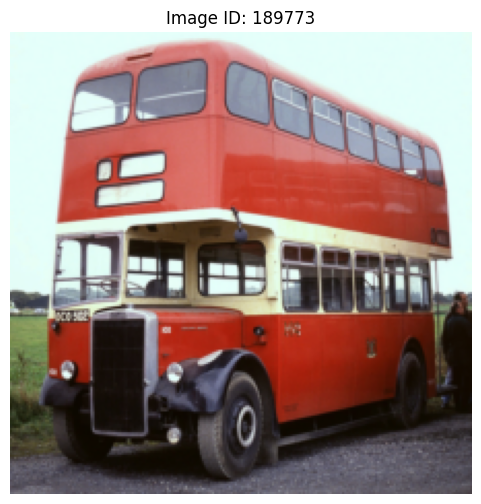


Total Q&A pairs: 4

Q1: What is the bus riding on?
A1: road

Q2: How many levels to the bus?
A2: 2

Q3: What is the bus driver doing?
A3: talking

Q4: What color is the bus?
A4: red



In [33]:
sanity_check_vqa_df(dataset,df)

### Data loading

In [34]:
from torch.utils.data import DataLoader
loader = DataLoader(dataset, batch_size=64, shuffle=True)


torch.Size([64, 3, 224, 224])
tensor([288890, 350463, 324158, 457687, 336587])


# Feature extraction

## Import required libraries

In [35]:
import torch
import torch.nn as nn
from torchvision import models

## Build class for loading the ResNet-50 and strip the final fully connected layer

In [36]:
class ResNet50FeatureExtractor(nn.Module):
    def __init__(self, pretrained=True):
        super().__init__()
        resnet = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1 if pretrained else None)
        self.backbone = nn.Sequential(*list(resnet.children())[:-1])

    def forward(self, x):
        x = self.backbone(x)
        x = x.flatten(start_dim=1)
        return x

### Print output

In [37]:
device = "cuda" if torch.cuda.is_available() else "cpu"
encoder = ResNet50FeatureExtractor(pretrained=True).to(device)

# Only evaluate, no model training
encoder.eval()

batch_imgs, batch_ids = next(iter(loader))
batch_imgs = batch_imgs.to(device)

with torch.no_grad():
    feats = encoder(batch_imgs)

print(feats.shape) # [64, 2048]


torch.Size([64, 2048])


## Build class for the CNN

In [38]:
class CustomCNN(nn.Module):
  def __init__(self):
    super().__init__()

    # Three convulotion block
    self.features = nn.Sequential(
            # Block 1
            nn.Conv2d(3, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),   # 224 -> 112

            # Block 2
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),   # 112 -> 56

            # Block 3
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),   # 56 -> 28
    )
    # Global Average Pooling
    self.gap = nn.AdaptiveAvgPool2d((1, 1))

    # Project to a 512-dim vector for better representation
    self.proj = nn.Linear(256, 512)

  def forward(self, x):
      x = self.features(x)          # (B, 256, 28, 28)
      x = self.gap(x)               # (B, 256, 1, 1)
      x = x.flatten(start_dim=1)    # (B, 256)
      x = self.proj(x)              # (B, 512)
      return x


### Print output

In [39]:
device = "cuda" if torch.cuda.is_available() else "cpu"
custom_encoder = CustomCNN().to(device)

# Only evaluate, no model training
encoder.eval()

with torch.no_grad():
    custom_feats = custom_encoder(batch_imgs)

print(custom_feats.shape) # [64, 512]


torch.Size([64, 512])
